# 05 Final test — the selected model on the untouched test days (run once)

HeatCast NCR (simple version) · workspace Section 6.4.

**What this notebook does.** The group selected the Random Forest of Section 5.2 / 6.3 (depth 12, at least 5 days per leaf, balanced class
weights, 500 trees, `RANDOM_STATE = 42`). Here it is fitted **once** on all training days (2021-01-01 to 2024-12-27) and scored **once** on
the test days (2024-12-29 to 2025-12-28, 365 days, 5,840 rows), which no notebook has used before. This is the same as
`final_test(model, train, test)` in `src/common.py`; the fit is written out here so that the predictions can be kept for the confusion
matrix and the per-level scores. Nothing is tuned or changed after looking at these numbers.

The "copy today" rule is scored on the same test days for comparison (it has no fitted parts).

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "common.py").exists():      # opened from notebooks/
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "src"))
from common import *
from make_dataset import LEVELS

OUT = ROOT / "results" / "final_test"
OUT.mkdir(parents=True, exist_ok=True)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Data and split (shared)

In [2]:
df = load_data()
train, test = split_train_test(df)
print(f"train {len(train):,} rows ({train.Date.min().date()} to {train.Date.max().date()}) | "
      f"test {len(test):,} rows ({test.Date.min().date()} to {test.Date.max().date()}, {test.Date.nunique()} days)")
pd.DataFrame({"training rows": train[TARGET].value_counts(), "test rows": test[TARGET].value_counts()}).reindex(LEVELS).fillna(0).astype(int)

train 23,312 rows (2021-01-01 to 2024-12-27) | test 5,840 rows (2024-12-29 to 2025-12-28, 365 days)


,training rows,test rows
HeatLevelTomorrow,,
Not Hazardous,40,0
Caution,3135,806
Extreme Caution,18304,4687
Danger,1833,347
Extreme Danger,0,0


## 2. The selected model (settings chosen in notebook 03 on the 5 folds only)

In [3]:
cv_summary = json.loads((ROOT / "results" / "random_forest" / "summary.json").read_text())
cfg = cv_summary["selected_config"]
print(cfg)
model = make_pipeline(make_preprocess(scale=False),
                      RandomForestClassifier(**cfg, random_state=RANDOM_STATE, n_jobs=-1))

{'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': 'balanced', 'n_estimators': 500}


## 3. The one fit and the one check

Same steps as `final_test()`: a fresh copy of the model, fitted on all training days, then scored on the test days.

In [4]:
fitted = clone(model).fit(train[FEATURES], train[TARGET])
pred = pd.Series(fitted.predict(test[FEATURES]), index=test.index, name="predicted")
copy_today = persistence_predictions(test)

scores = pd.DataFrame({"Random Forest": score(test[TARGET], pred),
                       "Copy today rule": score(test[TARGET], copy_today)}).T
scores.round(3)

,macro_f1,macro_f1_core3,accuracy,danger_recall,danger_precision
Random Forest,0.614,0.614,0.731,0.844,0.359
Copy today rule,0.675,0.675,0.824,0.597,0.597


## 4. Test scores next to the cross-validation scores

The fold scores (mean ± SD over the 5 folds) come from notebook 03. The test days are one more, later block of days, so a test score inside
the fold-to-fold spread is what we would expect.

In [5]:
metrics = ["macro_f1_core3", "macro_f1", "accuracy", "danger_recall", "danger_precision"]
side = pd.DataFrame({
    "RF test": scores.loc["Random Forest", metrics],
    "RF folds mean": [cv_summary["cv"][m]["mean"] for m in metrics],
    "RF folds SD": [cv_summary["cv"][m]["sd"] for m in metrics],
    "Copy today test": scores.loc["Copy today rule", metrics],
    "Copy today folds mean": [cv_summary["copy_today_cv"][m]["mean"] for m in metrics],
})
side.round(3)

,RF test,RF folds mean,RF folds SD,Copy today test,Copy today folds mean
macro_f1_core3,0.614,0.653,0.039,0.675,0.679
macro_f1,0.614,0.589,0.103,0.675,0.620
accuracy,0.731,0.794,0.035,0.824,0.846
danger_recall,0.844,0.672,0.193,0.597,0.518
danger_precision,0.359,0.402,0.113,0.597,0.527


## 5. Per-level scores on the test days

In [6]:
present = [lv for lv in LEVELS if lv in set(test[TARGET]) | set(pred) | set(copy_today)]
rows = []
for name, guess in [("Random Forest", pred), ("Copy today rule", copy_today)]:
    p, r, f, s = precision_recall_fscore_support(test[TARGET], guess, labels=present, zero_division=0)
    for lv, pi, ri, fi, si in zip(present, p, r, f, s):
        rows.append({"model": name, "level": lv, "precision": pi, "recall": ri, "f1": fi, "true days": int(si),
                     "predicted days": int((guess == lv).sum())})
per_level = pd.DataFrame(rows)
per_level.round(3)

,model,level,precision,recall,f1,true days,predicted days
0,Random Forest,Not Hazardous,0.000,0.000,0.000,0,18
1,Random Forest,Caution,0.431,0.670,0.525,806,1253
2,Random Forest,Extreme Caution,0.916,0.733,0.814,4687,3753
3,Random Forest,Danger,0.359,0.844,0.504,347,816
4,Copy today rule,Not Hazardous,0.000,0.000,0.000,0,0
5,Copy today rule,Caution,0.535,0.543,0.539,806,819
6,Copy today rule,Extreme Caution,0.891,0.889,0.890,4687,4674
7,Copy today rule,Danger,0.597,0.597,0.597,347,347


## 6. Confusion matrix (rows: true level, columns: predicted level)

,Not Hazardous,Caution,Extreme Caution,Danger
Not Hazardous,0,0,0,0
Caution,3,540,263,0
Extreme Caution,15,713,3436,523
Danger,0,0,54,293


,Not Hazardous,Caution,Extreme Caution,Danger
copy today,,,,
Not Hazardous,0,0,0,0
Caution,0,438,368,0
Extreme Caution,0,381,4166,140
Danger,0,0,140,207


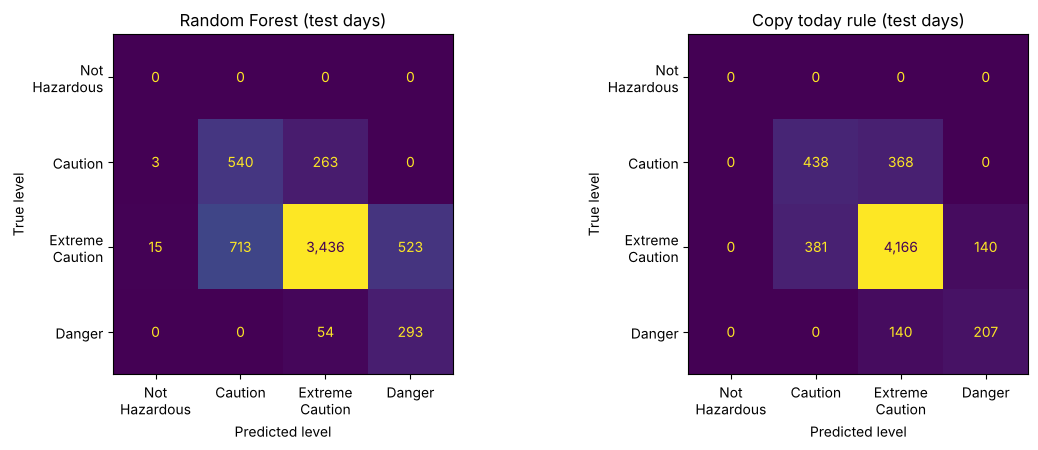

In [7]:
cm = pd.DataFrame(confusion_matrix(test[TARGET], pred, labels=present), index=present, columns=present)
cm_copy = pd.DataFrame(confusion_matrix(test[TARGET], copy_today, labels=present), index=present, columns=present)
display(cm)
display(cm_copy.rename_axis("copy today"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (title, m) in zip(axes, [("Random Forest (test days)", cm), ("Copy today rule (test days)", cm_copy)]):
    ConfusionMatrixDisplay(m.values, display_labels=[lv.replace(" ", "\n") for lv in present]).plot(ax=ax, colorbar=False, values_format=",d")
    ax.set_title(title)
    ax.set_xlabel("Predicted level"); ax.set_ylabel("True level")
fig.tight_layout()
fig.savefig(OUT / "figure_T1_confusion_matrix.png", dpi=150)

## 7. Danger days by month on the test days

Where the Danger days, the catches and the false alarms fall in the year.

In [8]:
month = test["Date"].dt.month
by_month = pd.DataFrame({
    "true Danger": (test[TARGET] == DANGER).groupby(month).sum(),
    "RF caught": ((test[TARGET] == DANGER) & (pred == DANGER)).groupby(month).sum(),
    "RF false alarms": ((test[TARGET] != DANGER) & (pred == DANGER)).groupby(month).sum(),
    "copy today caught": ((test[TARGET] == DANGER) & (copy_today == DANGER)).groupby(month).sum(),
    "copy today false alarms": ((test[TARGET] != DANGER) & (copy_today == DANGER)).groupby(month).sum(),
}).rename_axis("month")
by_month.loc["total"] = by_month.sum()
by_month

,true Danger,RF caught,RF false alarms,copy today caught,copy today false alarms
month,,,,,
1,0,0,1,0,0
2,0,0,0,0,0
3,3,3,14,0,3
4,118,101,162,69,43
5,136,131,203,103,39
6,63,44,56,28,35
7,0,0,9,0,0
8,12,5,24,4,8
9,0,0,8,0,0


## 8. Save the results

In [9]:
scores.round(4).to_csv(OUT / "test_scores.csv")
side.round(4).to_csv(OUT / "test_vs_cv.csv")
per_level.round(4).to_csv(OUT / "per_level_scores.csv", index=False)
cm.to_csv(OUT / "confusion_matrix.csv")
cm_copy.to_csv(OUT / "confusion_matrix_copy_today.csv")
by_month.to_csv(OUT / "danger_by_month.csv")

summary = {
    "model": "Random Forest", "config": cfg, "random_state": RANDOM_STATE,
    "trained_on": f"{train.Date.min().date()} to {train.Date.max().date()} ({len(train)} rows)",
    "tested_on": f"{test.Date.min().date()} to {test.Date.max().date()} ({len(test)} rows)",
    "test_scores": scores.loc["Random Forest"].to_dict(),
    "copy_today_test_scores": scores.loc["Copy today rule"].to_dict(),
    "danger_days": int((test[TARGET] == DANGER).sum()),
    "danger_caught": int(cm.loc[DANGER, DANGER]),
    "danger_called": int(cm[DANGER].sum()),
    "copy_today_danger_caught": int(cm_copy.loc[DANGER, DANGER]),
    "copy_today_danger_called": int(cm_copy[DANGER].sum()),
    "sklearn": sklearn.__version__,
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "model": "Random Forest",
  "config": {
    "max_depth": 12,
    "min_samples_leaf": 5,
    "class_weight": "balanced",
    "n_estimators": 500
  },
  "random_state": 42,
  "trained_on": "2021-01-01 to 2024-12-27 (23312 rows)",
  "tested_on": "2024-12-29 to 2025-12-28 (5840 rows)",
  "test_scores": {
    "macro_f1": 0.6142045940546081,
    "macro_f1_core3": 0.6142045940546083,
    "accuracy": 0.7309931506849315,
    "danger_recall": 0.8443804034582133,
    "danger_precision": 0.3590686274509804
  },
  "copy_today_test_scores": {
    "macro_f1": 0.6752315188060082,
    "macro_f1_core3": 0.6752315188060082,
    "accuracy": 0.8238013698630137,
    "danger_recall": 0.5965417867435159,
    "danger_precision": 0.5965417867435159
  },
  "danger_days": 347,
  "danger_caught": 293,
  "danger_called": 816,
  "copy_today_danger_caught": 207,
  "copy_today_danger_called": 347,
  "sklearn": "1.9.1"
}
